# Breast Cancer Classification Using BreaKHis
## Notebook 01: Dataset Audit, Grouped Evaluation, and Baseline Models

**Authors:** Aryan Patel and Kumkum Pathare  
**Scope:** study-plan stages 1–3: understand the dataset, validate grouped evaluation, and establish reference baselines.

This notebook studies binary classification of BreaKHis histopathology images as **benign** or **malignant**. It builds an auditable image manifest, checks labels and identifiers, creates group-separated folds, and compares a majority-class baseline, a CNN trained from scratch, and an ImageNet-pretrained ResNet18 with a frozen backbone.

The filename parser retains the complete `YEAR-SLIDE_ID` token, including any letter suffix. Short numeric prefixes are reported for inspection but are never used as grouping keys. If the same complete token appears under more than one subtype folder, those records share a group for splitting so that they cannot cross partitions; their subtype-specific `case_id` values remain separate for auditing.

> This is an academic research workflow, not a clinically validated diagnostic system. Filename-based groups are conservative grouping proxies, not independently verified clinical patient identities. Results on BreaKHis alone do not establish clinical utility or generalisation to other institutions.

Outputs are saved under `outputs/`, including the manifest, audit checks, identifier-collision report, optional group-mapping template, fold assignments, training histories, model checkpoints, predictions, and metrics.


## 1. Environment and dataset setup

Run this notebook in a Python environment with PyTorch, torchvision, scikit-learn, pandas, NumPy, Pillow, matplotlib, and tqdm installed. Google Colab with a GPU is recommended for the baseline runs. The download cell uses the dataset link published by the [official BreaKHis database page](https://web.inf.ufpr.br/vri/databases/breast-cancer-histopathological-database-breakhis/).

The public archive contains 7,909 images in the distribution described by the study plan. If you already have the dataset, set `BREAKHIS_ROOT` to the directory that contains the extracted BreaKHis folder tree. The notebook does not download anything when that environment variable points to an existing copy.

In [1]:
import hashlib
import io
import json
import math
import os
import random
import re
import sys
import tarfile
import time
import urllib.error
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from PIL import Image
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from tqdm.auto import tqdm

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)

EXPECTED_IMAGES = 7909
DATA_URL = os.environ.get(
    "BREAKHIS_URL",
    "http://www.inf.ufpr.br/vri/databases/BreaKHis_v1.tar.gz",
)
DATA_DIR = Path(os.environ.get("BREAKHIS_DATA_DIR", "./data")).expanduser()


### 1.1 Download or locate the dataset

The extraction helper checks every archive member before extraction and does not allow absolute paths or path traversal. If the download is interrupted, rerun the cell; the downloader attempts to resume when the server supports HTTP range requests. If the archive cannot be extracted or the expected number of images is not found, fix the dataset location before continuing.

In [2]:
def count_images(root: Path) -> int:
    return sum(1 for path in root.rglob("*") if path.is_file() and path.suffix.lower() == ".png" and path.name.startswith("SOB_"))


def download_file(url: str, dest: Path, chunk_size: int = 1 << 20) -> None:
    dest.parent.mkdir(parents=True, exist_ok=True)
    existing_size = dest.stat().st_size if dest.exists() else 0
    headers = {"Range": f"bytes={existing_size}-"} if existing_size else {}
    request = urllib.request.Request(url, headers=headers)

    try:
        response = urllib.request.urlopen(request, timeout=60)
    except urllib.error.HTTPError as exc:
        if exc.code == 416 and dest.exists():
            # Let extraction and image-count validation determine whether the local file is complete.
            return
        raise RuntimeError(f"Dataset download failed: HTTP {exc.code} for {url}") from exc
    except (urllib.error.URLError, TimeoutError) as exc:
        raise RuntimeError(f"Could not reach the dataset URL: {url}. Check the connection or set BREAKHIS_ROOT to a local copy.") from exc

    with response:
        resumed = existing_size > 0 and getattr(response, "status", None) == 206
        if not resumed:
            existing_size = 0
        total_size = existing_size + int(response.headers.get("Content-Length", 0))
        mode = "ab" if resumed else "wb"
        with dest.open(mode) as handle, tqdm(
            total=total_size or None,
            initial=existing_size,
            unit="B",
            unit_scale=True,
            desc=dest.name,
        ) as progress:
            while True:
                block = response.read(chunk_size)
                if not block:
                    break
                handle.write(block)
                progress.update(len(block))


def extract_archive(archive: Path, destination: Path) -> None:
    destination.mkdir(parents=True, exist_ok=True)
    root = destination.resolve()
    try:
        with tarfile.open(archive, mode="r:gz") as tar:
            members = tar.getmembers()
            for member in members:
                target = (destination / member.name).resolve()
                if not target.is_relative_to(root):
                    raise RuntimeError(f"Unsafe archive path rejected: {member.name!r}")
                if member.issym() or member.islnk():
                    raise RuntimeError(f"Archive link entry rejected: {member.name!r}")
            try:
                tar.extractall(destination, members=members, filter="data")
            except TypeError:
                # Older Python versions do not accept filter=; the path and link checks above still apply.
                tar.extractall(destination, members=members)
    except (tarfile.TarError, EOFError, OSError) as exc:
        raise RuntimeError(
            f"Could not extract {archive}. The archive may be incomplete or corrupt; remove it and retry."
        ) from exc


if os.environ.get("BREAKHIS_ROOT"):
    data_root_candidate = Path(os.environ["BREAKHIS_ROOT"]).expanduser()
    print(f"Using existing BREAKHIS_ROOT: {data_root_candidate.resolve()}")
else:
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    data_root_candidate = DATA_DIR
    found_before = count_images(data_root_candidate)
    if found_before < EXPECTED_IMAGES:
        archive_path = DATA_DIR / Path(DATA_URL).name
        print(f"Found {found_before:,} image files under {DATA_DIR.resolve()}; checking the official archive.")
        download_file(DATA_URL, archive_path)
        extract_archive(archive_path, DATA_DIR)
        found_after = count_images(DATA_DIR)
        if found_after < EXPECTED_IMAGES:
            raise RuntimeError(
                f"Expected at least {EXPECTED_IMAGES:,} BreaKHis PNG images after extraction, but found {found_after:,}. "
                f"Inspect {DATA_DIR.resolve()} and the archive {archive_path.resolve()} before continuing."
            )
    os.environ["BREAKHIS_ROOT"] = str(data_root_candidate.resolve())
    print(f"Dataset root set to: {data_root_candidate.resolve()}")

if not data_root_candidate.exists():
    raise FileNotFoundError(f"Dataset root does not exist: {data_root_candidate.resolve()}")


Found 0 image files under /kaggle/working/data; checking the official archive.


BreaKHis_v1.tar.gz:   0%|          | 0.00/4.27G [00:00<?, ?B/s]

Dataset root set to: /kaggle/working/data


## 2. Reproducible configuration

`folds_to_run=(0,)` is useful for a quick pipeline check. The default runs all five outer folds. The training configuration is recorded with each model run.

**Identifier policy used by this notebook:** `patient_id` is the full `YEAR-SLIDE_ID` token from the filename, including alphabetic suffixes (for example, `14-21998AB` and `14-21998CD` remain distinct). `number_key` deliberately removes the suffix and is only an audit aid; it is never used to merge groups. When the exact full token is shared across subtype folders (the BreaKHis `14-13412` DC/LC edge case), both diagnostic records are assigned to the same group for splitting, conservatively preventing potential leakage. The original subtype-specific `case_id` records remain unchanged.

An optional `outputs/patient_group_mapping.csv` can override the default grouping if you have stronger, documented patient-level information. It must contain one row per `case_id` and columns `case_id` and `patient_id`; it may merge additional case IDs when justified, but it may not split cases that share the same complete `YEAR-SLIDE_ID` token. Review the mapping before using it. Prefix collisions alone do not require a mapping file.


In [3]:
@dataclass
class Config:
    data_root: Path
    out_dir: Path
    seed: int = 42
    img_size: int = 224
    batch_size: int = 32
    epochs: int = 15
    patience: int = 4
    lr_cnn: float = 1e-3
    lr_head: float = 1e-3
    weight_decay: float = 1e-4
    n_outer_folds: int = 5
    n_inner_folds: int = 4
    folds_to_run: tuple | None = None
    num_workers: int = 2 if sys.platform.startswith("linux") else 0
    threshold: float = 0.5

    def __post_init__(self):
        if self.folds_to_run is None:
            self.folds_to_run = tuple(range(self.n_outer_folds))
        if self.img_size < 32:
            raise ValueError("img_size must be at least 32 pixels.")
        if self.batch_size < 1 or self.epochs < 1 or self.patience < 1:
            raise ValueError("batch_size, epochs, and patience must be positive integers.")
        if self.threshold != 0.5:
            raise ValueError(
                "This baseline notebook fixes the classification threshold at 0.5. "
                "Any non-default threshold must first be selected using validation data only."
            )
        if self.n_outer_folds < 2 or self.n_inner_folds < 2:
            raise ValueError("Both outer and inner fold counts must be at least 2.")
        if any(fold < 0 or fold >= self.n_outer_folds for fold in self.folds_to_run):
            raise ValueError("folds_to_run contains a fold outside the configured outer-fold range.")


cfg = Config(
    data_root=Path(os.environ.get("BREAKHIS_ROOT", str(data_root_candidate))).expanduser(),
    out_dir=Path(os.environ.get("BREAKHIS_OUT", "./outputs")).expanduser(),
)
cfg.out_dir.mkdir(parents=True, exist_ok=True)

# The full-token policy is documented in Section 2. Set False to enforce a manual pause.
IDENTIFIER_REVIEWED = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
ROLES = ("train", "val", "test")
CLASS_NAMES = ("benign", "malignant")
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True


set_seed(cfg.seed)
print(f"Device: {DEVICE} | PyTorch: {torch.__version__} | data root: {cfg.data_root.resolve()}")
if DEVICE.type == "cpu":
    print("Note: training on CPU may be slow. Enable a GPU runtime for the full baseline comparison.")


Device: cuda | PyTorch: 2.11.0+cu128 | data root: /kaggle/working/data


## 3. Build the image manifest

The filename parser follows the published BreaKHis filename structure and checks it against the directory hierarchy. The complete composite `case_id` is retained; the code **does not** collapse a slide identifier such as `22549AB` to the numeric prefix `22549`. Numeric-prefix collisions are retained in a review table because the filename alone should not be used to infer that two cases are one patient.

Every PNG discovered under `data_root` is represented in the manifest, including filenames that fail parsing. Unreadable or unparsed files therefore remain visible in the audit rather than being silently dropped.

In [4]:
FILENAME_RE = re.compile(
    r"^SOB_(?P<cls>[BM])_(?P<subtype>[A-Z]+)-(?P<year>\d{2})-(?P<slide>\d+[A-Z]*)-(?P<mag>\d+)-(?P<seq>\d+)\.png$",
    re.IGNORECASE,
)
SUBTYPE_NAMES = {
    "A": "adenosis",
    "F": "fibroadenoma",
    "PT": "phyllodes_tumor",
    "TA": "tubular_adenoma",
    "DC": "ductal_carcinoma",
    "LC": "lobular_carcinoma",
    "MC": "mucinous_carcinoma",
    "PC": "papillary_carcinoma",
}


def normalize_id(value: str) -> str:
    return re.sub(r"[^0-9a-z]", "", str(value).lower())


def parse_path(path: Path) -> dict | None:
    match = FILENAME_RE.match(path.name)
    if match is None:
        return None

    parsed = match.groupdict()
    class_code = parsed["cls"].upper()
    subtype_code = parsed["subtype"].upper()
    slide = parsed["slide"].upper()
    label = int(class_code == "M")
    parents = list(path.parents)

    def parent_name(index: int) -> str:
        return parents[index].name if len(parents) > index else ""

    numeric_prefix = re.match(r"\d+", slide)
    if numeric_prefix is None:
        return None

    case_id = f"SOB_{class_code}_{subtype_code}-{parsed['year']}-{slide}"
    return {
        "image_path": str(path),
        "case_id": case_id,
        # The full YEAR-SLIDE_ID token is the grouping candidate. Keep any letter suffix.
        "patient_id": f"{parsed['year']}-{slide}",
        "class_code": class_code,
        "label": label,
        "label_name": CLASS_NAMES[label],
        "subtype_code": subtype_code,
        "subtype": SUBTYPE_NAMES.get(subtype_code, subtype_code),
        "year": parsed["year"],
        "slide": slide,
        "number_key": f"{parsed['year']}-{numeric_prefix.group(0)}",
        "slide_id": f"{parsed['year']}-{slide}",
        "magnification": int(parsed["mag"]),
        "sequence": int(parsed["seq"]),
        "folder_mag": parent_name(0).upper(),
        "folder_slide": parent_name(1),
        "folder_subtype": parent_name(2).lower(),
        "folder_class": parent_name(4).lower(),
    }


def inspect_file(path_text: str) -> dict:
    info = {
        "readable": False,
        "width": np.nan,
        "height": np.nan,
        "color_mode": "",
        "sha256": "",
        "file_error": "",
    }
    try:
        raw = Path(path_text).read_bytes()
        info["sha256"] = hashlib.sha256(raw).hexdigest()
        with Image.open(io.BytesIO(raw)) as image_file:
            image_file.load()
            info["width"], info["height"] = image_file.size
            info["color_mode"] = image_file.mode
        info["readable"] = True
    except Exception as exc:
        info["file_error"] = f"{type(exc).__name__}: {exc}"
    return info


if not cfg.data_root.exists():
    raise FileNotFoundError(f"Dataset root does not exist: {cfg.data_root.resolve()}")

all_pngs = sorted(
    path for path in cfg.data_root.rglob("*")
    if path.is_file() and path.suffix.lower() == ".png"
)
if not all_pngs:
    raise FileNotFoundError(
        f"No PNG files found under {cfg.data_root.resolve()}. Set BREAKHIS_ROOT to the extracted BreaKHis dataset directory."
    )

manifest_rows = []
for image_path in all_pngs:
    parsed = parse_path(image_path)
    row = parsed or {
        "image_path": str(image_path),
        "case_id": "",
        "patient_id": "",
        "class_code": "",
        "label": np.nan,
        "label_name": "",
        "subtype_code": "",
        "subtype": "",
        "year": "",
        "slide": "",
        "number_key": "",
        "slide_id": "",
        "magnification": np.nan,
        "sequence": np.nan,
        "folder_mag": image_path.parent.name.upper(),
        "folder_slide": image_path.parent.parent.name if len(image_path.parents) > 1 else "",
        "folder_subtype": image_path.parent.parent.parent.name.lower() if len(image_path.parents) > 2 else "",
        "folder_class": image_path.parent.parent.parent.parent.parent.name.lower() if len(image_path.parents) > 4 else "",
    }
    row["filename_parse_ok"] = parsed is not None
    row["parse_error"] = "" if parsed is not None else "Filename did not match the documented BreaKHis naming pattern."
    manifest_rows.append(row)

manifest = pd.DataFrame(manifest_rows)
with ThreadPoolExecutor(max_workers=min(8, os.cpu_count() or 1)) as executor:
    file_info = list(tqdm(executor.map(inspect_file, manifest.image_path), total=len(manifest), desc="Checking PNG files"))
manifest = pd.concat([manifest.reset_index(drop=True), pd.DataFrame(file_info)], axis=1)

print(f"PNG files discovered: {len(manifest):,}")
print(f"Filenames parsed: {int(manifest.filename_parse_ok.sum()):,}")
print(f"Unreadable images: {int((~manifest.readable).sum()):,}")
display(manifest.head())


Checking PNG files:   0%|          | 0/7909 [00:00<?, ?it/s]

PNG files discovered: 7,909
Filenames parsed: 7,909
Unreadable images: 0


,image_path,case_id,patient_id,class_code,label,label_name,subtype_code,subtype,year,slide,number_key,slide_id,magnification,sequence,folder_mag,folder_slide,folder_subtype,folder_class,filename_parse_ok,parse_error,readable,width,height,color_mode,sha256,file_error
0,/kaggle/working/data/BreaKHis_v1/histology_sli...,SOB_B_A-14-22549AB,14-22549AB,B,0,benign,A,adenosis,14,22549AB,14-22549,14-22549AB,100,1,100X,SOB_B_A_14-22549AB,adenosis,benign,True,,True,700,460,RGB,17ee1b192eafa481d1123dea703f0f4369bba55201f19e...,
1,/kaggle/working/data/BreaKHis_v1/histology_sli...,SOB_B_A-14-22549AB,14-22549AB,B,0,benign,A,adenosis,14,22549AB,14-22549,14-22549AB,100,2,100X,SOB_B_A_14-22549AB,adenosis,benign,True,,True,700,460,RGB,459390da68d9f4862529583c34190a98a9dc6a6019a6b4...,
2,/kaggle/working/data/BreaKHis_v1/histology_sli...,SOB_B_A-14-22549AB,14-22549AB,B,0,benign,A,adenosis,14,22549AB,14-22549,14-22549AB,100,3,100X,SOB_B_A_14-22549AB,adenosis,benign,True,,True,700,460,RGB,ea865d8556ddcbf415368871a3a794c7339c88448d064b...,
3,/kaggle/working/data/BreaKHis_v1/histology_sli...,SOB_B_A-14-22549AB,14-22549AB,B,0,benign,A,adenosis,14,22549AB,14-22549,14-22549AB,100,4,100X,SOB_B_A_14-22549AB,adenosis,benign,True,,True,700,460,RGB,0fb6623c1842cf6970361a6439a6842f653e0ef77068c2...,
4,/kaggle/working/data/BreaKHis_v1/histology_sli...,SOB_B_A-14-22549AB,14-22549AB,B,0,benign,A,adenosis,14,22549AB,14-22549,14-22549AB,100,5,100X,SOB_B_A_14-22549AB,adenosis,benign,True,,True,700,460,RGB,416f11ea965d68cdc30cbf969fb22b4e21c2296f2cd3b3...,


## 4. Identifier review and dataset audit

The notebook distinguishes a **diagnostic case ID** (`SOB_<class>_<subtype>-<year>-<slide>`) from the **full filename patient token** (`<year>-<slide>`). The complete token, including any letter suffix, is the default grouping key. A shorter numeric prefix such as `14-21998` is not sufficient to identify a patient: `14-21998AB`, `14-21998CD`, and `14-21998EF` remain distinct groups unless independent metadata justifies merging them.

If one exact full token appears under multiple diagnostic subtypes, those records are grouped together for partitioning as a conservative leakage-prevention rule. In BreaKHis, `14-13412` appears in both the DC and LC categories; the diagnostic case rows remain separate in the manifest, but they will not be split across training, validation, and test partitions. Numeric-prefix collision reports are therefore informational; they are not automatic failures and do not require a mapping file.

The notebook creates `outputs/patient_group_mapping_template.csv` using the default full-token grouping. A custom mapping is optional and must cover every parsed `case_id` exactly once. Any additional merges should be supported by documented evidence. The audit still blocks on critical data errors, inconsistent binary labels within a group, or exact duplicate images requiring resolution.


In [5]:
parsed_mask = manifest["filename_parse_ok"]
parsed_manifest = manifest.loc[parsed_mask].copy()

case_table = (
    parsed_manifest.groupby("case_id", as_index=False)
    .agg(
        label=("label", "first"),
        label_name=("label_name", "first"),
        subtype_code=("subtype_code", "first"),
        subtype=("subtype", "first"),
        year=("year", "first"),
        slide=("slide", "first"),
        patient_id=("patient_id", "first"),
        number_key=("number_key", "first"),
        image_count=("image_path", "size"),
    )
)

mapping_template_path = cfg.out_dir / "patient_group_mapping_template.csv"
mapping_path = cfg.out_dir / "patient_group_mapping.csv"
case_table[["case_id", "patient_id", "label_name", "subtype_code", "number_key", "image_count"]].to_csv(
    mapping_template_path, index=False
)

GROUP_MAPPING_LOADED = mapping_path.exists()
MAPPING_VALID = True
if GROUP_MAPPING_LOADED:
    mapping = pd.read_csv(mapping_path, dtype=str).fillna("")
    required_mapping_columns = {"case_id", "patient_id"}
    if not required_mapping_columns.issubset(mapping.columns):
        raise ValueError(
            f"{mapping_path} must contain columns named case_id and patient_id. Found: {list(mapping.columns)}"
        )
    mapping["case_id"] = mapping["case_id"].astype(str).str.strip()
    mapping["patient_id"] = mapping["patient_id"].astype(str).str.strip()
    if mapping["case_id"].duplicated().any():
        raise ValueError("patient_group_mapping.csv contains duplicate case_id rows. Keep exactly one row per case_id.")
    expected_case_ids = set(case_table.case_id.astype(str))
    mapped_case_ids = set(mapping.case_id)
    missing_ids = sorted(expected_case_ids - mapped_case_ids)
    extra_ids = sorted(mapped_case_ids - expected_case_ids)
    blank_groups = mapping.loc[mapping.patient_id.eq(""), "case_id"].tolist()
    if missing_ids or extra_ids or blank_groups:
        raise ValueError(
            "The patient mapping does not cover the parsed dataset exactly. "
            f"Missing case IDs: {missing_ids[:8]}; unexpected IDs: {extra_ids[:8]}; blank group IDs: {blank_groups[:8]}."
        )
    mapping_dict = dict(zip(mapping.case_id, mapping.patient_id))

    # A custom map may merge different full tokens, but must not split an identical
    # full YEAR-SLIDE_ID token into separate groups.
    mapped_cases = case_table[["case_id", "patient_id"]].copy()
    mapped_cases["mapped_patient_id"] = mapped_cases["case_id"].map(mapping_dict)
    split_full_tokens = (
        mapped_cases.groupby("patient_id").mapped_patient_id.nunique()
    )
    split_full_tokens = split_full_tokens[split_full_tokens > 1]
    if len(split_full_tokens):
        raise ValueError(
            "patient_group_mapping.csv splits identical full filename patient token(s) across groups: "
            f"{split_full_tokens.index.tolist()[:10]}. Keep every case sharing the same full YEAR-SLIDE_ID token in one group."
        )

    manifest["patient_id"] = manifest["case_id"].map(mapping_dict).fillna("")
    print(f"Loaded reviewed group mapping: {mapping_path.resolve()}")
else:
    default_group_map = dict(zip(case_table.case_id, case_table.patient_id))
    manifest["patient_id"] = manifest["case_id"].map(default_group_map).fillna("")
    print("Using full YEAR-SLIDE_ID tokens as grouping IDs; numeric prefixes are audit-only.")

# Recalculate exact-duplicate indicators from file hashes. Do not silently discard duplicate images.
hash_counts = manifest.loc[manifest.readable & manifest.sha256.ne("")].groupby("sha256").image_path.nunique()
duplicate_hashes = set(hash_counts[hash_counts > 1].index)
manifest["is_duplicate"] = manifest.sha256.isin(duplicate_hashes)
duplicate_review = manifest.loc[manifest.is_duplicate].sort_values(["sha256", "image_path"])

# Numeric prefixes strip letter suffixes and are used only for an informational review table.
case_number_counts = case_table.groupby("number_key").case_id.nunique()
collision_keys = set(case_number_counts[case_number_counts > 1].index)
identifier_collisions = case_table.loc[case_table.number_key.isin(collision_keys)].sort_values(
    ["number_key", "patient_id", "case_id"]
)
identifier_collisions = identifier_collisions.assign(
    colliding_case_count=identifier_collisions.number_key.map(case_number_counts)
)

valid_readable = manifest.loc[manifest.filename_parse_ok & manifest.readable].copy()
label_count_by_group = valid_readable.groupby("patient_id").label.nunique()
subtype_count_by_group = valid_readable.groupby("patient_id").subtype_code.nunique()


def add_check(rows, name, observed, expected, mismatch_status="FAIL"):
    equal = observed == expected
    rows.append({
        "check": name,
        "observed": observed,
        "expected": expected,
        "status": "PASS" if equal else mismatch_status,
    })


check_rows = []
add_check(check_rows, "PNG image count", int(len(manifest)), EXPECTED_IMAGES, "FAIL")
add_check(check_rows, "Unparsed PNG filenames", int((~manifest.filename_parse_ok).sum()), 0, "FAIL")
add_check(check_rows, "Unreadable images", int((~manifest.readable).sum()), 0, "FAIL")
add_check(
    check_rows,
    "Filename class vs class folder mismatches",
    int((valid_readable.label_name != valid_readable.folder_class).sum()),
    0,
    "FAIL",
)
add_check(
    check_rows,
    "Filename subtype vs subtype folder mismatches",
    int((valid_readable.subtype != valid_readable.folder_subtype).sum()),
    0,
    "FAIL",
)
add_check(
    check_rows,
    "Filename case ID vs slide-folder mismatches",
    int((valid_readable.case_id.map(normalize_id) != valid_readable.folder_slide.map(normalize_id)).sum()),
    0,
    "FAIL",
)
add_check(
    check_rows,
    "Filename magnification vs magnification-folder mismatches",
    int((valid_readable.magnification.astype("Int64").astype(str) + "X" != valid_readable.folder_mag).sum()),
    0,
    "FAIL",
)
add_check(
    check_rows,
    "Unexpected magnification values",
    int((~valid_readable.magnification.isin([40, 100, 200, 400])).sum()),
    0,
    "FAIL",
)
add_check(
    check_rows,
    "Unknown subtype codes",
    int((~valid_readable.subtype_code.isin(SUBTYPE_NAMES)).sum()),
    0,
    "FAIL",
)
required_metadata_columns = ["case_id", "patient_id", "label", "subtype_code", "magnification", "width", "height"]
add_check(
    check_rows,
    "Rows missing required metadata",
    int(valid_readable[required_metadata_columns].isna().any(axis=1).sum()),
    0,
    "FAIL",
)
invalid_dimensions = valid_readable.width.isna() | valid_readable.height.isna() | (valid_readable.width <= 0) | (valid_readable.height <= 0)
add_check(
    check_rows,
    "Images with invalid dimensions",
    int(invalid_dimensions.sum()),
    0,
    "FAIL",
)
add_check(
    check_rows,
    "Groups containing more than one binary class label",
    int((label_count_by_group > 1).sum()),
    0,
    "FAIL",
)
add_check(
    check_rows,
    "Numeric-prefix collision keys (suffix retained; informational)",
    int(len(collision_keys)),
    0,
    "INFO",
)
add_check(
    check_rows,
    "Exact-duplicate image hash groups",
    int(len(duplicate_hashes)),
    0,
    "REVIEW",
)
add_check(
    check_rows,
    "Groups containing multiple subtype codes",
    int((subtype_count_by_group > 1).sum()),
    0,
    "INFO",
)
add_check(
    check_rows,
    "Non-RGB images (converted to RGB by the loader)",
    int((valid_readable.color_mode != "RGB").sum()),
    0,
    "INFO",
)

reference_counts = {
    "Benign images": (int((valid_readable.label == 0).sum()), 2480),
    "Malignant images": (int((valid_readable.label == 1).sum()), 5429),
    "Filename-derived case IDs": (int(case_table.case_id.nunique()), 82),
    "Benign filename-derived case IDs": (int((case_table.label == 0).sum()), 24),
    "Malignant filename-derived case IDs": (int((case_table.label == 1).sum()), 58),
    "Images at 40X": (int((valid_readable.magnification == 40).sum()), 1995),
    "Images at 100X": (int((valid_readable.magnification == 100).sum()), 2081),
    "Images at 200X": (int((valid_readable.magnification == 200).sum()), 2013),
    "Images at 400X": (int((valid_readable.magnification == 400).sum()), 1820),
}
for name, (observed, expected) in reference_counts.items():
    add_check(check_rows, name, observed, expected, "FAIL")

checks = pd.DataFrame(check_rows)
checks.to_csv(cfg.out_dir / "dataset_audit_checks.csv", index=False)
manifest.to_csv(cfg.out_dir / "manifest.csv", index=False)
identifier_collisions.to_csv(cfg.out_dir / "identifier_collision_review.csv", index=False)
duplicate_review.to_csv(cfg.out_dir / "duplicate_image_review.csv", index=False)

print("Dataset checks")
display(checks)
print(f"\nManifest saved: {(cfg.out_dir / 'manifest.csv').resolve()}")
print(f"Default group mapping template: {mapping_template_path.resolve()}")
print(f"Full-token grouping IDs: {valid_readable.patient_id.nunique():,}")
print(f"Diagnostic case IDs: {case_table.case_id.nunique():,}")
print(f"Numeric-prefix collision keys (informational): {len(collision_keys)}")
if len(identifier_collisions):
    display(identifier_collisions[["number_key", "patient_id", "case_id", "label_name", "subtype_code", "colliding_case_count"]])
if len(duplicate_review):
    print("Exact duplicate images found. Review duplicate_image_review.csv and resolve them before training.")
    display(duplicate_review[["image_path", "case_id", "patient_id", "label_name", "subtype", "sha256"]].head(20))


Using full YEAR-SLIDE_ID tokens as grouping IDs; numeric prefixes are audit-only.
Dataset checks


,check,observed,expected,status
0,PNG image count,7909,7909,PASS
1,Unparsed PNG filenames,0,0,PASS
2,Unreadable images,0,0,PASS
3,Filename class vs class folder mismatches,0,0,PASS
4,Filename subtype vs subtype folder mismatches,0,0,PASS
5,Filename case ID vs slide-folder mismatches,0,0,PASS
6,Filename magnification vs magnification-folder...,0,0,PASS
7,Unexpected magnification values,0,0,PASS
8,Unknown subtype codes,0,0,PASS
9,Rows missing required metadata,0,0,PASS



Manifest saved: /kaggle/working/outputs/manifest.csv
Default group mapping template: /kaggle/working/outputs/patient_group_mapping_template.csv
Full-token grouping IDs: 81
Diagnostic case IDs: 82
Numeric-prefix collision keys (informational): 10


,number_key,patient_id,case_id,label_name,subtype_code,colliding_case_count
29,14-13412,14-13412,SOB_M_DC-14-13412,malignant,DC,2
63,14-13412,14-13412,SOB_M_LC-14-13412,malignant,LC,2
4,14-14134,14-14134,SOB_B_F-14-14134,benign,F,2
5,14-14134,14-14134E,SOB_B_F-14-14134E,benign,F,2
64,14-15570,14-15570,SOB_M_LC-14-15570,malignant,LC,2
65,14-15570,14-15570C,SOB_M_LC-14-15570C,malignant,LC,2
19,14-16184,14-16184,SOB_B_TA-14-16184,benign,TA,2
20,14-16184,14-16184CD,SOB_B_TA-14-16184CD,benign,TA,2
72,14-18842,14-18842,SOB_M_MC-14-18842,malignant,MC,2
73,14-18842,14-18842D,SOB_M_MC-14-18842D,malignant,MC,2


## 5. Dataset summaries

These tables describe the parsed, readable images. Counts are reported by class and magnification, by filename-derived case, and by subtype. They are audit summaries, not model-performance results.

Image dimensions and colour modes


,width,height,color_mode,images
1,700,460,RGB,7835
0,700,456,RGB,74


Images by class and magnification


magnification,40,100,200,400,All
label_name,,,,,
benign,625,644,623,588,2480
malignant,1370,1437,1390,1232,5429
All,1995,2081,2013,1820,7909


Reviewed grouping IDs by class and magnification


magnification,40,100,200,400,All
label_name,,,,,
benign,24,24,24,24,24
malignant,57,57,57,57,57
All,81,81,81,81,81


Subtype summary


,label_name,subtype,groups,images
0,benign,adenosis,4,444
1,benign,fibroadenoma,10,1014
2,benign,phyllodes_tumor,3,453
3,benign,tubular_adenoma,7,569
4,malignant,ductal_carcinoma,38,3451
5,malignant,lobular_carcinoma,5,626
6,malignant,mucinous_carcinoma,9,792
7,malignant,papillary_carcinoma,6,560


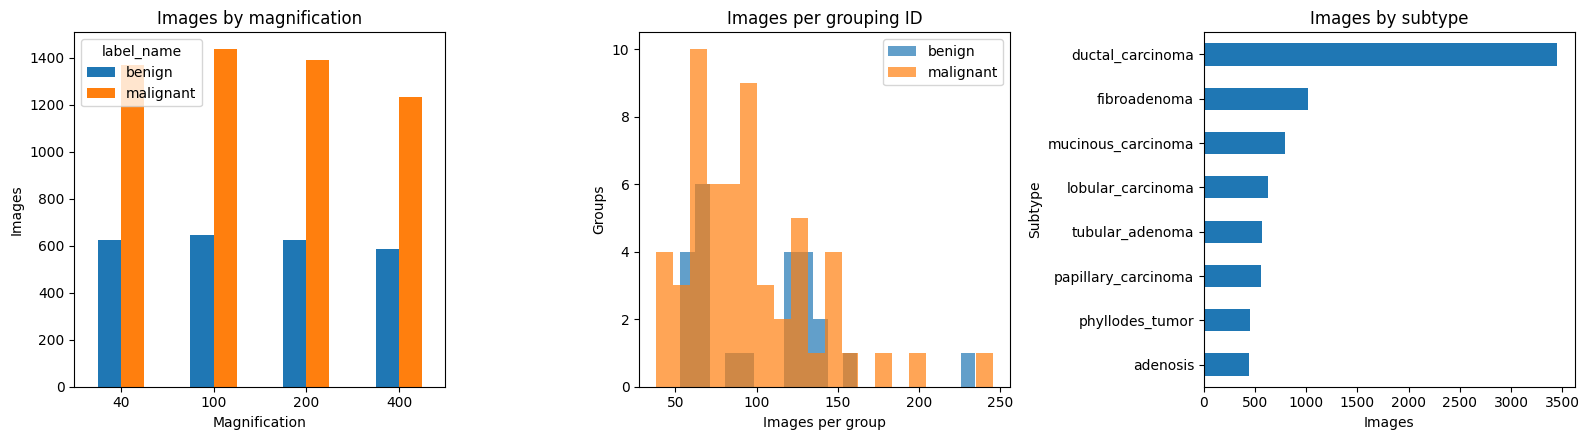

In [6]:
if len(valid_readable):
    image_counts = pd.crosstab(valid_readable.label_name, valid_readable.magnification, margins=True)
    group_table = (
        valid_readable.groupby("patient_id", as_index=False)
        .agg(
            label=("label", "first"),
            label_name=("label_name", "first"),
            subtype_count=("subtype_code", "nunique"),
            subtype=("subtype", lambda values: values.iloc[0] if values.nunique() == 1 else "MULTIPLE"),
            n_images=("image_path", "size"),
        )
    )
    group_table.to_csv(cfg.out_dir / "group_summary.csv", index=False)
    group_magnification_counts = valid_readable.groupby(["label_name", "magnification"]).patient_id.nunique().unstack(fill_value=0)
    group_magnification_counts["All"] = valid_readable.groupby("label_name").patient_id.nunique()
    all_groups_by_mag = valid_readable.groupby("magnification").patient_id.nunique()
    all_groups_by_mag["All"] = valid_readable.patient_id.nunique()
    group_magnification_counts.loc["All"] = all_groups_by_mag.reindex(group_magnification_counts.columns)
    group_magnification_counts = group_magnification_counts.fillna(0).astype(int)
    subtype_summary = (
        valid_readable.groupby(["label_name", "subtype"])
        .agg(groups=("patient_id", "nunique"), images=("image_path", "size"))
        .reset_index()
    )
    dimension_summary = (
        valid_readable.groupby(["width", "height", "color_mode"])
        .size()
        .rename("images")
        .reset_index()
        .sort_values("images", ascending=False)
    )

    print("Image dimensions and colour modes")
    display(dimension_summary)
    print("Images by class and magnification")
    display(image_counts)
    print("Reviewed grouping IDs by class and magnification")
    display(group_magnification_counts)
    print("Subtype summary")
    display(subtype_summary)

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    pd.crosstab(valid_readable.magnification, valid_readable.label_name).plot.bar(ax=axes[0], rot=0)
    axes[0].set(title="Images by magnification", xlabel="Magnification", ylabel="Images")
    for label_value, group in group_table.groupby("label"):
        axes[1].hist(group.n_images, bins=20, alpha=0.7, label=CLASS_NAMES[int(label_value)])
    axes[1].set(title="Images per grouping ID", xlabel="Images per group", ylabel="Groups")
    axes[1].legend()
    subtype_summary.set_index("subtype").images.sort_values().plot.barh(ax=axes[2])
    axes[2].set(title="Images by subtype", xlabel="Images", ylabel="Subtype")
    plt.tight_layout()
    plt.show()
else:
    print("No readable, parsed images are available for summaries.")


## 6. Decide whether the baseline pipeline is ready

The audit distinguishes real data-integrity failures from identifier-prefix warnings. Short numeric prefixes can be shared by multiple identifiers; the full `YEAR-SLIDE_ID` token, including letter suffixes, is used for grouping. Records with the same complete token share one group even when their subtype folders differ. The collision report is informational and does not require a custom mapping by itself.

Training is blocked if critical dataset checks fail, exact duplicate image content remains unresolved, or `IDENTIFIER_REVIEWED` is false. The default value is `True` because this notebook already applies the documented full-token policy; change it to `False` if you prefer to inspect the audit before allowing training. To continue:

1. Resolve unparsed/unreadable files and critical metadata or reference-count failures.
2. Inspect `identifier_collision_review.csv`; confirm the full-token grouping rule is appropriate for your copy of BreaKHis. Do not merge records using `number_key` alone.
3. Resolve exact duplicate images rather than silently counting them multiple times.
4. If you have a documented patient mapping, review `patient_group_mapping_template.csv`, create `patient_group_mapping.csv`, and rerun from the top. The mapping cannot split identical full patient tokens.
5. If you changed `IDENTIFIER_REVIEWED` to `False`, return it to `True` only after reviewing the audit and grouping policy, then rerun from the top.

`INFO` rows describe unusual but intentionally handled identifiers. They are not failures. A `REVIEW` or `FAIL` row still needs the action described above.


In [7]:
critical_failures = checks.loc[checks.status.eq("FAIL"), "check"].tolist()
blockers = []
if critical_failures:
    blockers.append("Critical dataset checks failed: " + "; ".join(critical_failures))
if len(duplicate_hashes):
    blockers.append(
        f"{len(duplicate_hashes)} exact-duplicate image hash group(s) remain. Resolve them before training."
    )
if not IDENTIFIER_REVIEWED:
    blockers.append(
        "IDENTIFIER_REVIEWED is False. Review the full-token grouping policy in Section 2, then set it to True and rerun from the top."
    )

BASELINES_READY = len(blockers) == 0
if BASELINES_READY:
    print("Dataset audit gate passed. Group-separated partitions may be created.")
else:
    print("BASELINE TRAINING IS BLOCKED")
    for item in blockers:
        print(f"- {item}")
    print("No baseline metrics will be produced until the blockers are resolved.")


Dataset audit gate passed. Group-separated partitions may be created.


## 7. Patient/group-separated partitions

Splits are created from **one row per reviewed grouping ID**, not one row per image. This makes stratification operate on group labels instead of letting patients with many images dominate the fold allocation. The outer five-fold split supplies the evaluation fold; an inner split of the remaining groups creates training and validation partitions. Validation data select checkpoints. Each outer test fold is reserved for evaluation within that fold, and its results are not used for that fold's model selection.

The exact same fold assignments are reused for each baseline.

In [8]:
def make_partitions(frame: pd.DataFrame, config) -> pd.DataFrame:
    group_labels = frame.groupby("patient_id", as_index=False).agg(label=("label", "first"))
    label_counts = group_labels.label.value_counts()
    if len(label_counts) != 2 or int(label_counts.min()) < config.n_outer_folds:
        raise ValueError(
            "Not enough independent groups in both classes for the requested outer folds. "
            f"Observed group counts: {label_counts.to_dict()}; n_outer_folds={config.n_outer_folds}."
        )

    outer = StratifiedKFold(
        n_splits=config.n_outer_folds,
        shuffle=True,
        random_state=config.seed,
    )
    assignment_rows = []
    for fold, (pool_idx, test_idx) in enumerate(outer.split(group_labels.patient_id, group_labels.label)):
        pool = group_labels.iloc[pool_idx].reset_index(drop=True)
        test_groups = group_labels.iloc[test_idx].patient_id.tolist()
        pool_counts = pool.label.value_counts()
        if len(pool_counts) != 2 or int(pool_counts.min()) < config.n_inner_folds:
            raise ValueError(
                f"Outer fold {fold} does not have enough groups per class for inner stratification: {pool_counts.to_dict()}"
            )
        inner = StratifiedKFold(
            n_splits=config.n_inner_folds,
            shuffle=True,
            random_state=config.seed + fold + 1,
        )
        train_idx, val_idx = next(inner.split(pool.patient_id, pool.label))
        role_groups = {
            "train": pool.iloc[train_idx].patient_id.tolist(),
            "val": pool.iloc[val_idx].patient_id.tolist(),
            "test": test_groups,
        }
        for role, group_ids in role_groups.items():
            assignment_rows.extend(
                {"outer_fold": fold, "role": role, "patient_id": group_id}
                for group_id in group_ids
            )
    return pd.DataFrame(assignment_rows)


def get_partition(frame: pd.DataFrame, assignments: pd.DataFrame, fold: int) -> dict:
    fold_assignments = assignments.loc[assignments.outer_fold.eq(fold)]
    return {
        role: frame.loc[frame.patient_id.isin(fold_assignments.loc[fold_assignments.role.eq(role), "patient_id"])].reset_index(drop=True)
        for role in ROLES
    }


def check_class_presence(parts: dict, roles=ROLES) -> None:
    for role in roles:
        classes = set(parts[role].label.dropna().astype(int).unique())
        if classes != {0, 1}:
            raise ValueError(f"The {role} partition must contain both classes, but contains {sorted(classes)}.")


def check_partitions(frame: pd.DataFrame, assignments: pd.DataFrame) -> pd.DataFrame:
    all_groups = set(frame.patient_id.dropna())
    test_counts = assignments.loc[assignments.role.eq("test")].groupby("patient_id").size()
    if set(test_counts.index) != all_groups or not test_counts.eq(1).all():
        raise AssertionError("Every group must be a test group in exactly one outer fold.")
    if assignments.duplicated(["outer_fold", "patient_id"]).any():
        raise AssertionError("A group has more than one role within an outer fold.")

    group_label_counts = frame.groupby("patient_id").label.nunique()
    if (group_label_counts > 1).any():
        raise AssertionError("At least one group has inconsistent class labels.")
    group_labels = frame.groupby("patient_id").label.first()

    reports = []
    for fold, fold_frame in assignments.groupby("outer_fold"):
        role_sets = {
            role: set(fold_frame.loc[fold_frame.role.eq(role), "patient_id"])
            for role in ROLES
        }
        if role_sets["train"] & role_sets["val"]:
            raise AssertionError(f"Fold {fold}: training and validation groups overlap.")
        if role_sets["train"] & role_sets["test"]:
            raise AssertionError(f"Fold {fold}: training and test groups overlap.")
        if role_sets["val"] & role_sets["test"]:
            raise AssertionError(f"Fold {fold}: validation and test groups overlap.")
        if set.union(*role_sets.values()) != all_groups:
            raise AssertionError(f"Fold {fold}: some groups are missing from the partitions.")

        for role in ROLES:
            labels_in_role = group_labels.loc[list(role_sets[role])]
            if len(labels_in_role) == 0 or set(labels_in_role.astype(int).unique()) != {0, 1}:
                raise AssertionError(f"Fold {fold}: {role} does not contain both classes at the group level.")

        # This should be zero after the duplicate-image audit; keep it as a second guard.
        role_frame = frame[["patient_id", "sha256"]].drop_duplicates().merge(fold_frame, on="patient_id", how="inner")
        duplicate_role_counts = role_frame.loc[role_frame.sha256.ne("")].groupby("sha256").role.nunique()
        duplicate_hashes_across_roles = int((duplicate_role_counts > 1).sum())
        reports.append({
            "outer_fold": int(fold),
            "train_groups": len(role_sets["train"]),
            "validation_groups": len(role_sets["val"]),
            "test_groups": len(role_sets["test"]),
            "duplicate_hashes_across_roles": duplicate_hashes_across_roles,
        })
    report = pd.DataFrame(reports).sort_values("outer_fold").reset_index(drop=True)
    if report.duplicate_hashes_across_roles.sum() > 0:
        raise AssertionError("Exact duplicate image hashes cross roles. The split is not safe to use.")
    return report


# Test the split algorithm independently of the BreaKHis files.
from types import SimpleNamespace

synthetic_rows = []
for group_number in range(40):
    label = int(group_number % 5 in (0, 1))
    for image_number in range(2):
        synthetic_rows.append({
            "patient_id": f"synthetic_group_{group_number:02d}",
            "label": label,
            "image_path": f"synthetic_{group_number:02d}_{image_number}.png",
            "sha256": f"synthetic_hash_{group_number:02d}_{image_number}",
        })
synthetic_frame = pd.DataFrame(synthetic_rows)
synthetic_config = SimpleNamespace(n_outer_folds=5, n_inner_folds=4, seed=42)
synthetic_assignments = make_partitions(synthetic_frame, synthetic_config)
synthetic_report = check_partitions(synthetic_frame, synthetic_assignments)
assert (synthetic_report.duplicate_hashes_across_roles == 0).all()
print("Synthetic split self-test passed: group separation and outer-fold coverage are valid.")

if BASELINES_READY:
    df = valid_readable.copy().reset_index(drop=True)
    patient_table = (
        df.groupby("patient_id", as_index=False)
        .agg(label=("label", "first"), subtype=("subtype", "first"), n_images=("image_path", "size"))
    )
    assignments = make_partitions(df, cfg)
    overlap_report = check_partitions(df, assignments)
    display(overlap_report)
    assignments.to_csv(cfg.out_dir / "partitions.csv", index=False)
    print(f"Saved group-separated assignments: {(cfg.out_dir / 'partitions.csv').resolve()}")
else:
    df = valid_readable.copy().reset_index(drop=True)
    patient_table = pd.DataFrame(columns=["patient_id", "label", "subtype", "n_images"])
    assignments = pd.DataFrame(columns=["outer_fold", "role", "patient_id"])
    overlap_report = pd.DataFrame()
    print("Partition creation skipped because the dataset audit gate has not passed.")


Synthetic split self-test passed: group separation and outer-fold coverage are valid.


,outer_fold,train_groups,validation_groups,test_groups,duplicate_hashes_across_roles
0,0,48,16,17,0
1,1,48,17,16,0
2,2,48,17,16,0
3,3,48,17,16,0
4,4,48,17,16,0


Saved group-separated assignments: /kaggle/working/outputs/partitions.csv


## 8. Partition summaries and image loading

The summary reports both group and image counts, because the number of images per group can vary substantially. The baseline uses direct square resizing and ImageNet channel normalization for model inputs. No augmentation is applied in this first baseline; augmentation and aspect-ratio-preserving resizing belong to later controlled experiments.

In [9]:
def partition_summary(frame: pd.DataFrame, assignments: pd.DataFrame) -> pd.DataFrame:
    merged = frame.merge(assignments, on="patient_id", how="inner")
    image_summary = (
        merged.groupby(["outer_fold", "role"])
        .agg(
            groups=("patient_id", "nunique"),
            images=("image_path", "size"),
            malignant_image_fraction=("label", "mean"),
        )
    )
    group_labels = assignments.merge(
        frame[["patient_id", "label"]].drop_duplicates(),
        on="patient_id",
        how="left",
    )
    group_summary = (
        group_labels.groupby(["outer_fold", "role"]).agg(
            malignant_groups=("label", "sum"),
            groups_with_label=("label", "size"),
        )
    )
    result = image_summary.join(group_summary)
    result["malignant_image_fraction"] = result.malignant_image_fraction.round(3)
    return result


if BASELINES_READY:
    display(partition_summary(df, assignments))
else:
    print("Partition summaries are unavailable until the audit gate passes.")


eval_tf = transforms.Compose([
    transforms.Resize((cfg.img_size, cfg.img_size)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
# The initial baseline deliberately applies no augmentation; validation and test preprocessing are deterministic.
train_tf = eval_tf


class BreaKHisDataset(Dataset):
    def __init__(self, frame: pd.DataFrame, transform):
        self.paths = frame.image_path.astype(str).tolist()
        self.labels = frame.label.astype(int).to_numpy()
        self.transform = transform
        if not self.paths:
            raise ValueError("Cannot create a dataset from an empty partition.")

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image_file:
            image_tensor = self.transform(image_file.convert("RGB"))
        return image_tensor, int(self.labels[index])


def seed_worker(worker_id: int) -> None:
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_loaders(parts: dict, config: Config) -> dict:
    generator = torch.Generator()
    generator.manual_seed(config.seed)
    common_args = {
        "batch_size": config.batch_size,
        "num_workers": config.num_workers,
        "pin_memory": DEVICE.type == "cuda",
        "worker_init_fn": seed_worker,
        "persistent_workers": config.num_workers > 0,
        "drop_last": False,
    }
    return {
        role: DataLoader(
            BreaKHisDataset(parts[role], train_tf if role == "train" else eval_tf),
            shuffle=(role == "train"),
            generator=generator if role == "train" else None,
            **common_args,
        )
        for role in ROLES
    }


groups  images  malignant_image_fraction  malignant_groups  groups_with_label
outer_fold role                                                                                
0          test       17    1456                     0.775                12                 17
           train      48    4812                     0.654                33                 48
           val        16    1641                     0.703                12                 16
1          test       16    1427                     0.747                12                 16
           train      48    4764                     0.702                33                 48
           val        17    1718                     0.594                12                 17
2          test       16    1572                     0.674                11                 16
           train      48    4982                     0.682                34                 48
           val        17    1355                     0.715                12                 17
3          test       16    1701                     0.628                11                 16
           train      48    4757                     0.696                34                 48
           val        17    1451                     0.725                12                 17
4          test       16    1753                     0.631                11                 16
           train      48    4601                     0.715                34                 48
           val        17    1555                     0.665                12                 17

## 9. Metrics and their self-checks

Metrics use malignant as the positive class (`1`). We report accuracy, balanced accuracy, malignant sensitivity, specificity, precision, malignant F1-score, ROC-AUC, and confusion-matrix counts. ROC-AUC uses predicted probabilities. If a metric is undefined because one class is absent, it is returned as `NaN` rather than being silently fabricated; each evaluation partition is separately required to contain both classes.

In [10]:
def binary_metrics(y_true, probabilities, threshold=0.5) -> dict:
    y_true = np.asarray(y_true, dtype=int)
    probabilities = np.asarray(probabilities, dtype=float)
    if y_true.ndim != 1 or probabilities.ndim != 1 or len(y_true) != len(probabilities):
        raise ValueError("y_true and probabilities must be one-dimensional arrays of equal length.")
    if len(y_true) == 0:
        raise ValueError("Cannot calculate metrics for an empty evaluation set.")
    if not np.isfinite(probabilities).all():
        raise ValueError("Predicted probabilities contain NaN or infinite values.")
    if ((probabilities < 0) | (probabilities > 1)).any():
        raise ValueError("Predicted probabilities must be in [0, 1].")
    if not 0 <= threshold <= 1:
        raise ValueError("threshold must be in [0, 1].")

    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    sensitivity = tp / (tp + fn) if (tp + fn) else np.nan
    specificity = tn / (tn + fp) if (tn + fp) else np.nan
    precision = tp / (tp + fp) if (tp + fp) else np.nan
    f1_malignant = (2 * tp / (2 * tp + fp + fn)) if (2 * tp + fp + fn) else 0.0
    balanced_accuracy = (sensitivity + specificity) / 2 if np.isfinite(sensitivity) and np.isfinite(specificity) else np.nan
    auc = roc_auc_score(y_true, probabilities) if len(np.unique(y_true)) == 2 else np.nan

    return {
        "accuracy": (tp + tn) / len(y_true),
        "balanced_accuracy": balanced_accuracy,
        "sensitivity": sensitivity,
        "specificity": specificity,
        "precision": precision,
        "f1_malignant": f1_malignant,
        "roc_auc": auc,
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
        "n": int(len(y_true)),
    }


def aggregate_patients(predictions: pd.DataFrame) -> pd.DataFrame:
    grouped = predictions.groupby("patient_id", dropna=False)
    if (grouped.label.nunique() != 1).any():
        raise ValueError("At least one grouping ID has inconsistent labels in the predictions.")
    return grouped.agg(
        label=("label", "first"),
        prob=("prob", "mean"),
        n_images=("prob", "size"),
    ).reset_index()


def verify_metrics() -> None:
    rng = np.random.default_rng(0)
    labels = rng.integers(0, 2, 500)
    probabilities = np.clip(0.3 * labels + 0.7 * rng.random(500), 0, 1)
    predicted = (probabilities >= 0.5).astype(int)
    measured = binary_metrics(labels, probabilities)
    expected = {
        "accuracy": accuracy_score(labels, predicted),
        "balanced_accuracy": balanced_accuracy_score(labels, predicted),
        "sensitivity": recall_score(labels, predicted, zero_division=0),
        "specificity": recall_score(labels, predicted, pos_label=0, zero_division=0),
        "precision": precision_score(labels, predicted, zero_division=0),
        "f1_malignant": f1_score(labels, predicted, zero_division=0),
        "roc_auc": roc_auc_score(labels, probabilities),
    }
    for metric_name, expected_value in expected.items():
        if not np.isclose(measured[metric_name], expected_value):
            raise AssertionError(f"Metric self-check failed for {metric_name}: {measured[metric_name]} != {expected_value}")

    all_positive = binary_metrics(labels, np.ones(len(labels)))
    assert np.isclose(all_positive["balanced_accuracy"], 0.5)
    assert np.isclose(all_positive["roc_auc"], 0.5)
    assert np.isclose(all_positive["sensitivity"], 1.0)
    assert np.isclose(all_positive["specificity"], 0.0)

    no_positive_predictions = binary_metrics(labels, np.zeros(len(labels)))
    assert np.isnan(no_positive_predictions["precision"])
    assert no_positive_predictions["f1_malignant"] == 0.0
    assert np.isclose(no_positive_predictions["sensitivity"], 0.0)
    assert np.isclose(no_positive_predictions["specificity"], 1.0)

    one_class = binary_metrics(np.ones(10, dtype=int), np.full(10, 0.9))
    assert np.isnan(one_class["specificity"]) and np.isnan(one_class["roc_auc"])
    print("Metric self-check passed against scikit-learn and edge cases.")


verify_metrics()


Metric self-check passed against scikit-learn and edge cases.


## 10. Baseline models

The three reference models are:

1. **Majority class:** always predicts the most common class in the training partition.
2. **CNN from scratch:** a compact convolutional model with batch normalisation and dropout.
3. **ResNet18 with a frozen backbone:** ImageNet-pretrained convolutional features with a newly trained two-class head. Fine-tuning is kept for a later controlled experiment.

The same patient/group folds, metric definitions, image size, and deterministic evaluation preprocessing are used for each model.

In [11]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=2, widths=(32, 64, 128, 128, 256), dropout=0.3):
        super().__init__()
        layers = []
        in_channels = 3
        for out_channels in widths:
            layers.extend([
                nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(kernel_size=2),
            ])
            in_channels = out_channels
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(in_channels, n_classes),
        )

    def forward(self, inputs):
        return self.head(self.features(inputs))


class TransferResNet18(nn.Module):
    def __init__(self, n_classes=2, freeze_backbone=True, pretrained=True):
        super().__init__()
        weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        self.backbone = models.resnet18(weights=weights)
        self.backbone.fc = nn.Identity()
        self.head = nn.Linear(512, n_classes)
        self.freeze_backbone = freeze_backbone
        if freeze_backbone:
            for parameter in self.backbone.parameters():
                parameter.requires_grad = False

    def train(self, mode=True):
        super().train(mode)
        if self.freeze_backbone:
            self.backbone.eval()
        return self

    def forward(self, inputs):
        return self.head(self.backbone(inputs))


def count_parameters(model):
    total = sum(parameter.numel() for parameter in model.parameters())
    trainable = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
    return total, trainable


MODEL_SPECS = {
    "cnn_scratch": {"build": lambda: SmallCNN(), "lr_attr": "lr_cnn"},
    "resnet18_frozen": {"build": lambda: TransferResNet18(freeze_backbone=True, pretrained=True), "lr_attr": "lr_head"},
}
MODEL_ORDER = ["majority", *MODEL_SPECS]

for model_name, model in {
    "cnn_scratch": SmallCNN(),
    "resnet18_frozen_structure_check": TransferResNet18(pretrained=False),
}.items():
    total_params, trainable_params = count_parameters(model)
    print(f"{model_name}: {total_params:,} parameters ({trainable_params:,} trainable)")


cnn_scratch: 537,122 parameters (537,122 trainable)
resnet18_frozen_structure_check: 11,177,538 parameters (1,026 trainable)


## 11. Training and checkpoint selection

Each neural model is trained on the training partition. The checkpoint is selected by validation ROC-AUC; the test partition is not used for model selection. Class-weighted cross-entropy and AdamW are used for both learned baselines. The configuration, class weights, training time, history, and checkpoint are saved per fold and model.

In [12]:
def make_scaler(enabled: bool):
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=enabled)


def cpu_state(model):
    return {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}


@torch.no_grad()
def predict(model, loader, criterion=None):
    model.eval()
    probabilities = []
    total_loss = 0.0
    sample_count = 0
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        logits = model(images)
        if criterion is not None:
            loss = criterion(logits, labels)
            total_loss += loss.item() * len(labels)
        probabilities.append(torch.softmax(logits.float(), dim=1)[:, 1].cpu())
        sample_count += len(labels)
    if sample_count == 0:
        raise ValueError("Prediction loader is empty.")
    probability_array = torch.cat(probabilities).numpy()
    average_loss = total_loss / sample_count if criterion is not None else np.nan
    return probability_array, average_loss


def train_model(name, model, loaders, parts, learning_rate, run_dir):
    check_class_presence(parts, ("train", "val"))
    run_dir.mkdir(parents=True, exist_ok=True)
    model = model.to(DEVICE)

    class_counts = np.bincount(parts["train"].label.astype(int).to_numpy(), minlength=2)
    if (class_counts == 0).any():
        raise ValueError(f"{name}: training partition is missing a class: {class_counts.tolist()}")
    class_weights = torch.tensor(
        class_counts.sum() / (2.0 * class_counts), dtype=torch.float32, device=DEVICE
    )
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.AdamW(
        [parameter for parameter in model.parameters() if parameter.requires_grad],
        lr=learning_rate,
        weight_decay=cfg.weight_decay,
    )
    scaler = make_scaler(USE_AMP)

    validation_labels = parts["val"].label.astype(int).to_numpy()
    best = {"auc": -np.inf, "epoch": 0, "state": None}
    history_rows = []
    start_time = time.time()

    for epoch in range(1, cfg.epochs + 1):
        model.train()
        running_loss = 0.0
        seen = 0
        for images, labels in tqdm(loaders["train"], desc=f"{name} | epoch {epoch}", leave=False):
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                loss = criterion(model(images), labels)
            if not math.isfinite(loss.item()):
                raise RuntimeError(f"{name}: training loss became non-finite at epoch {epoch}.")
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            running_loss += loss.item() * len(labels)
            seen += len(labels)

        if seen == 0:
            raise RuntimeError(f"{name}: training loader produced no batches. Reduce batch size or inspect the partition.")
        validation_probabilities, validation_loss = predict(model, loaders["val"], criterion)
        if not math.isfinite(validation_loss):
            raise RuntimeError(f"{name}: validation loss became non-finite at epoch {epoch}.")
        validation_metrics = binary_metrics(validation_labels, validation_probabilities, cfg.threshold)
        train_loss = running_loss / seen
        validation_auc = validation_metrics["roc_auc"]
        history_rows.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": validation_loss,
            "val_roc_auc": validation_auc,
            "val_balanced_accuracy": validation_metrics["balanced_accuracy"],
        })
        print(
            f"{name} | epoch {epoch:02d} | train loss {train_loss:.4f} | "
            f"validation loss {validation_loss:.4f} | validation ROC-AUC {validation_auc:.4f}"
        )

        if np.isfinite(validation_auc) and validation_auc > best["auc"]:
            best.update(auc=float(validation_auc), epoch=epoch, state=cpu_state(model))
        elif epoch - best["epoch"] >= cfg.patience:
            print(f"{name}: early stopping after epoch {epoch}.")
            break

    if best["state"] is None:
        raise RuntimeError(f"{name}: no checkpoint could be selected from validation ROC-AUC.")
    model.load_state_dict(best["state"])
    torch.save(best["state"], run_dir / "best.pt")
    history = pd.DataFrame(history_rows)
    history.to_csv(run_dir / "history.csv", index=False)
    run_info = {
        "model": name,
        "config": {key: (str(value) if isinstance(value, Path) else value) for key, value in asdict(cfg).items()},
        "learning_rate": learning_rate,
        "optimizer": "AdamW",
        "class_weights": class_weights.detach().cpu().tolist(),
        "selection_rule": "maximum validation ROC-AUC",
        "best_epoch": best["epoch"],
        "epochs_run": int(len(history)),
        "train_seconds": round(time.time() - start_time, 1),
        "train_groups": int(parts["train"].patient_id.nunique()),
        "validation_groups": int(parts["val"].patient_id.nunique()),
        "test_groups": int(parts["test"].patient_id.nunique()),
    }
    (run_dir / "run_info.json").write_text(json.dumps(run_info, indent=2), encoding="utf-8")
    return model, history


## 12. Run the baselines

Before starting, confirm that the audit gate above says it passed. For a short smoke run, set `cfg.folds_to_run = (0,)` and reduce `cfg.epochs` in Section 2. For the reported baseline comparison, run all five outer folds. ImageNet weights for ResNet18 may need to be downloaded by torchvision the first time it is instantiated.

In [13]:
def evaluate_predictions(model_name, fold, frame, probabilities):
    if len(frame) != len(probabilities):
        raise ValueError(f"{model_name}: received {len(probabilities)} predictions for {len(frame)} images.")
    image_predictions = frame[
        ["image_path", "case_id", "patient_id", "label", "label_name", "magnification", "subtype"]
    ].copy()
    image_predictions = image_predictions.assign(
        prob=np.asarray(probabilities, dtype=float),
        model=model_name,
        fold=int(fold),
    )
    group_predictions = aggregate_patients(image_predictions)
    metric_rows = [
        {"fold": int(fold), "model": model_name, "level": "image", **binary_metrics(image_predictions.label, image_predictions.prob, cfg.threshold)},
        {"fold": int(fold), "model": model_name, "level": "group", **binary_metrics(group_predictions.label, group_predictions.prob, cfg.threshold)},
    ]
    return metric_rows, image_predictions


def run_fold(fold):
    parts = get_partition(df, assignments, fold)
    check_class_presence(parts)
    group_sets = {role: set(parts[role].patient_id) for role in ROLES}
    if group_sets["train"] & group_sets["val"] or group_sets["train"] & group_sets["test"] or group_sets["val"] & group_sets["test"]:
        raise AssertionError(f"Fold {fold}: overlap detected after partition construction.")

    test_frame = parts["test"]
    fold_metric_rows = []
    fold_predictions = []
    fold_histories = {}

    majority_class = int(parts["train"].label.mean() >= 0.5)
    majority_probabilities = np.full(len(test_frame), float(majority_class), dtype=float)
    metric_rows, prediction_frame = evaluate_predictions("majority", fold, test_frame, majority_probabilities)
    fold_metric_rows.extend(metric_rows)
    fold_predictions.append(prediction_frame)

    for model_name, specification in MODEL_SPECS.items():
        set_seed(cfg.seed)
        loaders = make_loaders(parts, cfg)
        run_dir = cfg.out_dir / "runs" / f"fold_{fold}" / model_name
        try:
            model = specification["build"]()
        except Exception as exc:
            raise RuntimeError(
                f"Could not construct {model_name}. For ResNet18, check torchvision compatibility and network access for pretrained weights."
            ) from exc
        trained_model, history = train_model(
            model_name,
            model,
            loaders,
            parts,
            getattr(cfg, specification["lr_attr"]),
            run_dir,
        )
        test_probabilities, _ = predict(trained_model, loaders["test"])
        metric_rows, prediction_frame = evaluate_predictions(model_name, fold, test_frame, test_probabilities)
        fold_metric_rows.extend(metric_rows)
        fold_predictions.append(prediction_frame)
        fold_histories[model_name] = history

    return fold_metric_rows, pd.concat(fold_predictions, ignore_index=True), fold_histories


results = pd.DataFrame()
predictions = pd.DataFrame()
all_histories = {}
BASELINES_RAN = False

if BASELINES_READY:
    all_metric_rows = []
    all_prediction_frames = []
    for fold in cfg.folds_to_run:
        print(f"\n===== Outer fold {fold} =====")
        fold_rows, fold_predictions, fold_histories = run_fold(fold)
        all_metric_rows.extend(fold_rows)
        all_prediction_frames.append(fold_predictions)
        all_histories[fold] = fold_histories

    results = pd.DataFrame(all_metric_rows)
    predictions = pd.concat(all_prediction_frames, ignore_index=True)
    results.to_csv(cfg.out_dir / "results.csv", index=False)
    predictions.to_csv(cfg.out_dir / "predictions.csv", index=False)
    BASELINES_RAN = True
    print(f"Saved metrics: {(cfg.out_dir / 'results.csv').resolve()}")
    print(f"Saved predictions: {(cfg.out_dir / 'predictions.csv').resolve()}")
else:
    print("Baseline training skipped: resolve the dataset review blockers and rerun from the top.")



===== Outer fold 0 =====


cnn_scratch | epoch 1:   0%|          | 0/151 [00:00<?, ?it/s]

cnn_scratch | epoch 01 | train loss 0.3979 | validation loss 0.4384 | validation ROC-AUC 0.8561


cnn_scratch | epoch 2:   0%|          | 0/151 [00:00<?, ?it/s]

cnn_scratch | epoch 02 | train loss 0.2957 | validation loss 0.2118 | validation ROC-AUC 0.9685


...

resnet18_frozen | epoch 13 | train loss 0.2682 | validation loss 0.6068 | validation ROC-AUC 0.8336


resnet18_frozen | epoch 14:   0%|          | 0/144 [00:00<?, ?it/s]

resnet18_frozen | epoch 14 | train loss 0.2620 | validation loss 0.5709 | validation ROC-AUC 0.8359


resnet18_frozen | epoch 15:   0%|          | 0/144 [00:00<?, ?it/s]

resnet18_frozen | epoch 15 | train loss 0.2594 | validation loss 0.6337 | validation ROC-AUC 0.8383
Saved metrics: /kaggle/working/outputs/results.csv
Saved predictions: /kaggle/working/outputs/predictions.csv


## 13. Results and controlled subgroup reporting

The primary summaries report image-level and group-level results per outer fold, followed by fold means and standard deviations. The group-level estimate is only as credible as the reviewed grouping map. Subgroup performance is also reported by magnification with image and group counts; small subgroup counts should be interpreted cautiously.

In [14]:
METRIC_COLUMNS = [
    "accuracy", "balanced_accuracy", "sensitivity", "specificity", "precision", "f1_malignant", "roc_auc"
]

if BASELINES_RAN:
    results["model"] = pd.Categorical(results.model, MODEL_ORDER, ordered=True)
    majority_predictions = predictions.loc[predictions.model.eq("majority")]
    test_sizes = majority_predictions.groupby("fold").agg(
        test_images=("image_path", "size"),
        test_groups=("patient_id", "nunique"),
    )
    print("Evaluation partition sizes")
    display(test_sizes)

    for level in ("image", "group"):
        print(f"\n{level.capitalize()}-level metrics by model (mean over the executed folds)")
        display(
            results.loc[results.level.eq(level)]
            .groupby("model", observed=True)[METRIC_COLUMNS]
            .mean()
            .round(3)
        )
        if results.fold.nunique() > 1:
            print(f"{level.capitalize()}-level fold-to-fold standard deviation")
            display(
                results.loc[results.level.eq(level)]
                .groupby("model", observed=True)[METRIC_COLUMNS]
                .std()
                .round(3)
            )

    magnification_rows = []
    for (model_name, fold, magnification), subgroup in predictions.groupby(["model", "fold", "magnification"], observed=True):
        group_predictions = aggregate_patients(subgroup)
        magnification_rows.append({
            "model": model_name,
            "fold": int(fold),
            "magnification": int(magnification),
            "level": "image",
            "n_images": int(len(subgroup)),
            "n_groups": int(subgroup.patient_id.nunique()),
            **binary_metrics(subgroup.label, subgroup.prob, cfg.threshold),
        })
        magnification_rows.append({
            "model": model_name,
            "fold": int(fold),
            "magnification": int(magnification),
            "level": "group",
            "n_images": int(len(subgroup)),
            "n_groups": int(group_predictions.patient_id.nunique()),
            **binary_metrics(group_predictions.label, group_predictions.prob, cfg.threshold),
        })
    magnification_results = pd.DataFrame(magnification_rows)
    magnification_results.to_csv(cfg.out_dir / "magnification_results.csv", index=False)
    print("Per-magnification metrics (fold-level rows; check n_images and n_groups before interpretation)")
    display(magnification_results.sort_values(["level", "model", "magnification", "fold"]).round(3))

    non_majority = predictions.loc[predictions.model.ne("majority")].copy()
    non_majority["predicted_label"] = (non_majority.prob >= cfg.threshold).astype(int)
    errors = non_majority.loc[non_majority.predicted_label.ne(non_majority.label)].copy()
    errors["error_type"] = np.where(errors.predicted_label.eq(1), "false_positive", "false_negative")
    errors.to_csv(cfg.out_dir / "misclassified_examples.csv", index=False)
    print(f"Saved {len(errors)} misclassified image predictions for review.")
    if len(errors):
        display(
            errors.groupby(["model", "error_type", "magnification", "subtype"], dropna=False)
            .size()
            .rename("n_images")
            .reset_index()
            .sort_values("n_images", ascending=False)
            .head(20)
        )
else:
    print("Results and subgroup metrics are not available because the baseline models have not been run.")


Evaluation partition sizes


,test_images,test_groups
fold,,
0,1456,17
1,1427,16
2,1572,16
3,1701,16
4,1753,16



Image-level metrics by model (mean over the executed folds)


,accuracy,balanced_accuracy,sensitivity,specificity,precision,f1_malignant,roc_auc
model,,,,,,,
majority,0.691,0.500,1.000,0.000,0.691,0.816,0.500
cnn_scratch,0.778,0.790,0.775,0.804,0.907,0.825,0.868
resnet18_frozen,0.812,0.814,0.839,0.789,0.896,0.860,0.892


Image-level fold-to-fold standard deviation


...

,accuracy,balanced_accuracy,sensitivity,specificity,precision,f1_malignant,roc_auc
model,,,,,,,
majority,0.027,0.000,0.000,0.000,0.027,0.018,0.000
cnn_scratch,0.031,0.040,0.108,0.179,0.071,0.029,0.091
resnet18_frozen,0.080,0.122,0.108,0.283,0.106,0.057,0.069


Per-magnification metrics (fold-level rows; check n_images and n_groups before interpretation)


,model,fold,magnification,level,n_images,n_groups,accuracy,balanced_accuracy,sensitivity,specificity,precision,f1_malignant,roc_auc,tn,fp,fn,tp,n
1,cnn_scratch,0,40,group,374,17,0.765,0.775,0.750,0.800,0.900,0.818,0.867,4,1,3,9,17
9,cnn_scratch,1,40,group,343,16,0.688,0.792,0.583,1.000,1.000,0.737,0.958,4,0,5,7,16
17,cnn_scratch,2,40,group,400,16,0.875,0.800,1.000,0.600,0.846,0.917,0.764,3,2,0,11,16
25,cnn_scratch,3,40,group,437,16,0.875,0.855,0.909,0.800,0.909,0.909,0.927,4,1,1,10,16
33,cnn_scratch,4,40,group,441,16,0.812,0.864,0.727,1.000,1.000,0.842,1.000,5,0,3,8,16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
86,resnet18_frozen,0,400,image,326,17,0.801,0.867,0.734,1.000,1.000,0.846,0.968,82,0,65,179,326
94,resnet18_frozen,1,400,image,344,16,0.817,0.858,0.773,0.943,0.975,0.863,0.902,83,5,58,198,344
102,resnet18_frozen,2,400,image,363,16,0.771,0.723,0.878,0.568,0.795,0.834,0.769,71,54,29,209,363
110,resnet18_frozen,3,400,image,396,16,0.735,0.691,0.885,0.497,0.736,0.804,0.807,76,77,28,215,396


Saved 3230 misclassified image predictions for review.


,model,error_type,magnification,subtype,n_images
0,cnn_scratch,false_negative,40,ductal_carcinoma,167
4,cnn_scratch,false_negative,100,ductal_carcinoma,138
8,cnn_scratch,false_negative,200,ductal_carcinoma,122
12,cnn_scratch,false_negative,400,ductal_carcinoma,115
36,resnet18_frozen,false_negative,100,ductal_carcinoma,100
32,resnet18_frozen,false_negative,40,ductal_carcinoma,86
40,resnet18_frozen,false_negative,200,ductal_carcinoma,86
6,cnn_scratch,false_negative,100,mucinous_carcinoma,80
44,resnet18_frozen,false_negative,400,ductal_carcinoma,75
3,cnn_scratch,false_negative,40,papillary_carcinoma,72


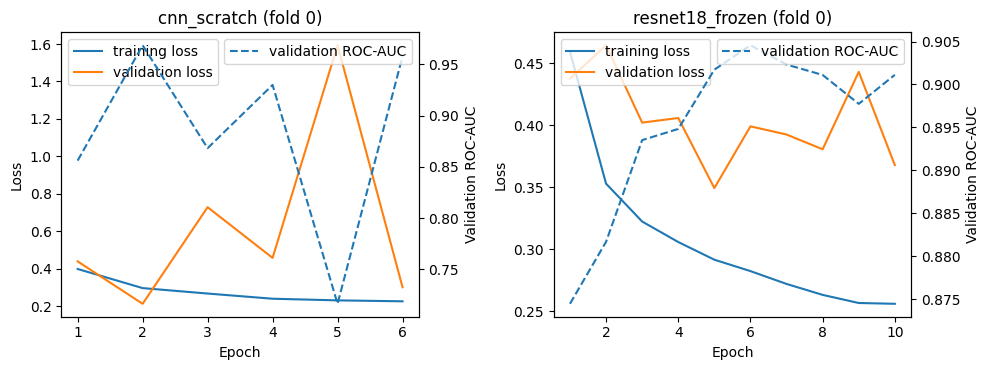

In [15]:
if BASELINES_RAN:
    first_fold = cfg.folds_to_run[0]
    fold_histories = all_histories[first_fold]
    if fold_histories:
        fig, axes = plt.subplots(
            1,
            len(fold_histories),
            figsize=(5 * len(fold_histories), 3.8),
            squeeze=False,
        )
        for axis, (model_name, history) in zip(axes[0], fold_histories.items()):
            axis.plot(history.epoch, history.train_loss, label="training loss")
            axis.plot(history.epoch, history.val_loss, label="validation loss")
            secondary_axis = axis.twinx()
            secondary_axis.plot(history.epoch, history.val_roc_auc, linestyle="--", label="validation ROC-AUC")
            secondary_axis.set_ylabel("Validation ROC-AUC")
            axis.set(title=f"{model_name} (fold {first_fold})", xlabel="Epoch", ylabel="Loss")
            axis.legend(loc="upper left")
            secondary_axis.legend(loc="upper right")
        plt.tight_layout()
        plt.show()
else:
    print("Training curves will appear after the baseline runs complete.")


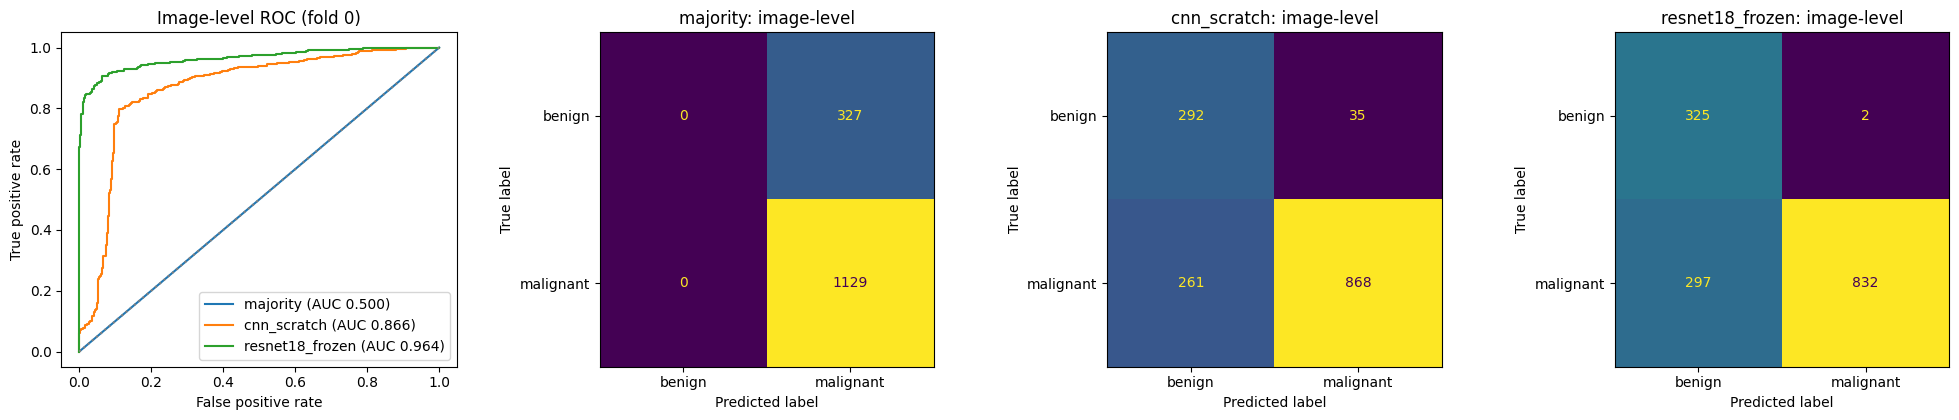

In [16]:
if BASELINES_RAN:
    first_fold = cfg.folds_to_run[0]
    fold_predictions = predictions.loc[predictions.fold.eq(first_fold)]
    fig, axes = plt.subplots(1, len(MODEL_ORDER) + 1, figsize=(5 * (len(MODEL_ORDER) + 1), 4.3))

    for model_name in MODEL_ORDER:
        subset = fold_predictions.loc[fold_predictions.model.eq(model_name)]
        false_positive_rate, true_positive_rate, _ = roc_curve(subset.label, subset.prob)
        auc = roc_auc_score(subset.label, subset.prob)
        axes[0].plot(false_positive_rate, true_positive_rate, label=f"{model_name} (AUC {auc:.3f})")
    axes[0].plot([0, 1], [0, 1], linestyle=":", color="grey")
    axes[0].set(
        title=f"Image-level ROC (fold {first_fold})",
        xlabel="False positive rate",
        ylabel="True positive rate",
    )
    axes[0].legend(loc="lower right")

    for axis, model_name in zip(axes[1:], MODEL_ORDER):
        subset = fold_predictions.loc[fold_predictions.model.eq(model_name)]
        ConfusionMatrixDisplay.from_predictions(
            subset.label.astype(int),
            (subset.prob >= cfg.threshold).astype(int),
            labels=[0, 1],
            display_labels=CLASS_NAMES,
            ax=axis,
            colorbar=False,
        )
        axis.set_title(f"{model_name}: image-level")
    plt.tight_layout()
    plt.show()
else:
    print("ROC curves and confusion matrices will appear after the baseline runs complete.")


## 14. Interpretation, deliverables, and next steps

Before reporting a score, retain the audit outputs and document the grouping policy. By default, groups use the full `YEAR-SLIDE_ID` token, including letter suffixes; subtype-specific `case_id` values stay separate in the manifest. Shared short numeric prefixes are reported for audit only. The `14-13412` record appears under both DC and LC and is kept in one split group as a conservative leakage-prevention decision. The notebook stores the manifest, audit checks, identifier collision report, duplicate review file, group mapping template, partition assignments, per-run configuration, histories, checkpoints, predictions, fold metrics, magnification metrics, and misclassified examples.

Recommended next steps from the study plan are to review the baseline's fold-to-fold variation, examine false positives and false negatives, and then conduct one controlled experiment at a time: augmentation, aspect-ratio-preserving resizing, partial/unfrozen ResNet18 fine-tuning, magnification-specific analysis, or stain normalisation. Keep the patient/group partitions fixed across comparisons wherever possible. Grad-CAM, if added later, should be interpreted as a qualitative inspection aid, not as proof that a model has learned medically meaningful features.

**Limitations:** grouping uses the complete filename identifier as a conservative proxy because the distributed filenames do not provide a separate clinical patient metadata table. The repeated `14-13412` token is grouped together across DC and LC to avoid possible cross-split leakage; the true biological identity cannot be established from the filenames alone. For publication-grade patient-level claims, report this grouping decision and perform a sensitivity analysis if an authoritative patient map is available. Published scores are meaningful comparisons only when the dataset, task, evaluation unit, and split protocol are comparable. This notebook does not produce a clinically validated diagnostic tool.

**Dataset citation:** F. Spanhol, L. S. Oliveira, C. Petitjean, and L. Heutte, “A Dataset for Breast Cancer Histopathological Image Classification,” *IEEE Transactions on Biomedical Engineering*, 63(7), 1455–1462, 2016. See the [official BreaKHis page](https://web.inf.ufpr.br/vri/databases/breast-cancer-histopathological-database-breakhis/) for dataset terms and citation guidance.